# U.S. Occupational Wage Analysis and Prediction

### Which factors best explain wage differences across U.S. labor markets, and how accurately can wages be predicted?

In [1]:
import nbformat
import re
from pathlib import Path
from IPython.display import Markdown, display

notebook = nbformat.read(
    Path('US Occupational Wage Analysis and Prediction.ipynb'),
    as_version=4
)

toc = ['## Table of Contents', '']

for cell in notebook.cells:
    if cell.cell_type != 'markdown':
        continue

    for line in cell.source.splitlines():
        match = re.match(r'^(#{1,3})\s+(.+)$', line)

        if match:
            level = len(match.group(1))
            title = match.group(2).strip()

            if title.lower() == 'table of contents':
                continue

            anchor = re.sub(r'[^\w -]', '', title.lower())
            anchor = re.sub(r'\s+', '-', anchor).strip('-')

            indent = '  ' * (level - 1)
            toc.append(f'{indent}- [{title}](#{anchor})')

display(Markdown('\n'.join(toc)))

## Table of Contents

- [U.S. Occupational Wage Analysis and Prediction](#us-occupational-wage-analysis-and-prediction)
    - [Which factors best explain wage differences across U.S. labor markets, and how accurately can wages be predicted?](#which-factors-best-explain-wage-differences-across-us-labor-markets-and-how-accurately-can-wages-be-predicted)
  - [Executive Summary](#executive-summary)
    - [Key Findings](#key-findings)
    - [Business Implications](#business-implications)
  - [1. Load Libraries and Data](#1-load-libraries-and-data)
  - [2. Data Quality Checks](#2-data-quality-checks)
  - [3. Exploratory Data Analysis (EDA)](#3-exploratory-data-analysis-eda)
    - [3.1 Mean Annual Wage by Major Occupation Group](#31-mean-annual-wage-by-major-occupation-group)
    - [3.2 Mean Annual Wage by Location](#32-mean-annual-wage-by-location)
    - [3.3 Mean Annual Wage by Employment Size](#33-mean-annual-wage-by-employment-size)
  - [4. Standalone Explanatory Power of Individual Variables](#4-standalone-explanatory-power-of-individual-variables)
  - [5. Progressive Multiple Linear Regression](#5-progressive-multiple-linear-regression)
    - [5.1 Comparing Model Fit and Incremental Explanatory Power](#51-comparing-model-fit-and-incremental-explanatory-power)
    - [5.2 Interpreting Regression Coefficients](#52-interpreting-regression-coefficients)
  - [6. Predictive Modeling: Linear Regression, Decision Tree, and Random Forest](#6-predictive-modeling-linear-regression-decision-tree-and-random-forest)
    - [6.1 Train/Test Split and Feature Preprocessing](#61-traintest-split-and-feature-preprocessing)
    - [6.2 Baseline and Regression Models](#62-baseline-and-regression-models)
    - [6.3 Initial Model Comparison](#63-initial-model-comparison)
    - [6.4 Hyperparameter Tuning](#64-hyperparameter-tuning)
    - [6.5 Final Model Evaluation and Comparison](#65-final-model-evaluation-and-comparison)
  - [7. Business Recommendations and Limitations](#7-business-recommendations-and-limitations)

## Executive Summary

This analysis examines wage variation across U.S. geographic areas and major occupation groups. The objectives are to identify which factors are most strongly associated with differences in mean annual wages and evaluate whether these factors can support wage prediction for labor-market benchmarking and workforce planning.

The analysis combines **exploratory data analysis, descriptive statistics, correlation analysis, and multiple linear regression** to examine the relationships between occupation, geographic area, employment size, and mean annual wages. **Progressive regression models** quantify the incremental explanatory power of each variable. The analysis then compares **Linear Regression, Decision Tree Regression, and Random Forest Regression** against a simple baseline, using cross-validation for model selection and a held-out test set for final evaluation.

### Key Findings
1. **Major occupation has the strongest relationship with wages.** Differences across major occupation groups explain approximately 83.8% of the variation in mean annual wages.
2. **Location also matters substantially.** After accounting for occupation, geographic differences explain an additional 9.4% of wage variation, increasing the model's explanatory power from 83.8% to 93.2%.
3. **Employment size has a relatively small relationship with wages.** After accounting for occupation and location, employment size adds only about 0.5%, bringing the final model to approximately 93.7% explanatory power.
4. Linear Regression provides the most accurate predictions among the models evaluated. It achieved a test-set MAE of approximately `$5,003`, an RMSE of `$7,069`, and an R² of 0.939.

### Business Implications

The findings support an occupation-first, geography-second approach to wage benchmarking. Businesses should establish wage benchmarks based on the type of work being performed, then account for geographic labor-market differences.

The selected Linear Regression model could support preliminary wage comparisons across major occupation groups and geographic areas and help with early-stage workforce budget planning. Its average absolute prediction error of approximately $5,003 per annual wage estimate should be considered when interpreting predictions. Before using the model for compensation decisions, businesses should evaluate prediction errors across occupations and locations and validate performance against more recent wage data.

Because the model uses aggregated occupation-level estimates rather than individual employee data, more granular salary information would be needed for decisions involving specific job titles, experience levels, or individual compensation.


#### Dataset

The dataset is the U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS), May 2024 state estimates workbook. It includes occupational employment and wage estimates across the geographic areas published in the workbook, including states and other reported areas.

**Main fields used**

| Field | Description |
|---|---|
| `AREA_TITLE` | Geographic area name |
| `OCC_TITLE` | Occupation or occupation-group title |
| `O_GROUP` | Occupation aggregation level |
| `TOT_EMP` | Estimated employment |
| `A_MEAN` | Estimated mean annual wage |
| `A_MEDIAN` | Estimated median annual wage |

## 1. Load Libraries and Data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# SciPy provides the hypothesis tests used in this analysis.
from scipy.stats import pearsonr
# Statsmodels provides regression models and statistical inference.
import statsmodels.formula.api as smf

# Machine learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
#Formats displayed floating-point values with thousands separators and three decimal places.
#, adds thousands separators.
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

DATA_FOLDER = Path('US Occupational Wage Analysis datasets')
df_raw = pd.read_excel(DATA_FOLDER / 'state_M2024_dl.xlsx')
df = df_raw.copy()

## 2. Data Quality Checks

In [3]:
df = df[['AREA_TITLE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'A_MEAN']]

Major occupation groups are used as the primary level of analysis because they provide a balance between granularity and interpretability.

In [4]:
df['O_GROUP'].value_counts()

O_GROUP
detailed    36367
major        1188
total          54
Name: count, dtype: int64

In [5]:
df[df['O_GROUP'] == 'total'].head()

,AREA_TITLE,OCC_TITLE,O_GROUP,TOT_EMP,A_MEAN
0,Alabama,All Occupations,total,2091480,55350
736,Alaska,All Occupations,total,321040,72810
1300,Arizona,All Occupations,total,3196750,65740
2043,Arkansas,All Occupations,total,1288810,53070
2741,California,All Occupations,total,18057850,79900


In [6]:
df[df['O_GROUP'] == 'major'].head()

,AREA_TITLE,OCC_TITLE,O_GROUP,TOT_EMP,A_MEAN
1,Alabama,Management Occupations,major,110240,118670
37,Alabama,Business and Financial Operations Occupations,major,108720,82220
67,Alabama,Computer and Mathematical Occupations,major,57260,101140
87,Alabama,Architecture and Engineering Occupations,major,50130,105480
120,Alabama,"Life, Physical, and Social Science Occupations",major,12740,77430


In [7]:
df = df[df['O_GROUP'] == 'major']
df = df[['AREA_TITLE', 'OCC_TITLE', 'TOT_EMP', 'A_MEAN']]

In [8]:
df.shape

(1188, 4)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1188 entries, 1 to 37595
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   AREA_TITLE  1188 non-null   object
 1   OCC_TITLE   1188 non-null   object
 2   TOT_EMP     1188 non-null   object
 3   A_MEAN      1188 non-null   object
dtypes: object(4)
memory usage: 46.4+ KB


In [10]:
df.isna().sum()

AREA_TITLE    0
OCC_TITLE     0
TOT_EMP       0
A_MEAN        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['TOT_EMP'].value_counts()

TOT_EMP
17000     3
5910      2
76210     2
17620     2
28180     2
         ..
14430     1
28410     1
16070     1
106820    1
2280      1
Name: count, Length: 1154, dtype: int64

In [13]:
df['A_MEAN'].value_counts()

A_MEAN
45400    4
51800    3
57090    3
47310    3
63170    3
        ..
41310    1
41680    1
50730    1
54120    1
39870    1
Name: count, Length: 1094, dtype: int64

In [14]:
df.head()

,AREA_TITLE,OCC_TITLE,TOT_EMP,A_MEAN
1,Alabama,Management Occupations,110240,118670
37,Alabama,Business and Financial Operations Occupations,108720,82220
67,Alabama,Computer and Mathematical Occupations,57260,101140
87,Alabama,Architecture and Engineering Occupations,50130,105480
120,Alabama,"Life, Physical, and Social Science Occupations",12740,77430


In [15]:
# Convert analytical variables to numeric
df['TOT_EMP'] = pd.to_numeric(
    df['TOT_EMP'],
    errors='coerce'
)

df['A_MEAN'] = pd.to_numeric(
    df['A_MEAN'],
    errors='coerce'
)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1188 entries, 1 to 37595
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   AREA_TITLE  1188 non-null   object 
 1   OCC_TITLE   1188 non-null   object 
 2   TOT_EMP     1188 non-null   int64  
 3   A_MEAN      1186 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 46.4+ KB


In [17]:
df = df.dropna(subset='A_MEAN')

## 3. Exploratory Data Analysis (EDA)

### 3.1 Mean Annual Wage by Major Occupation Group

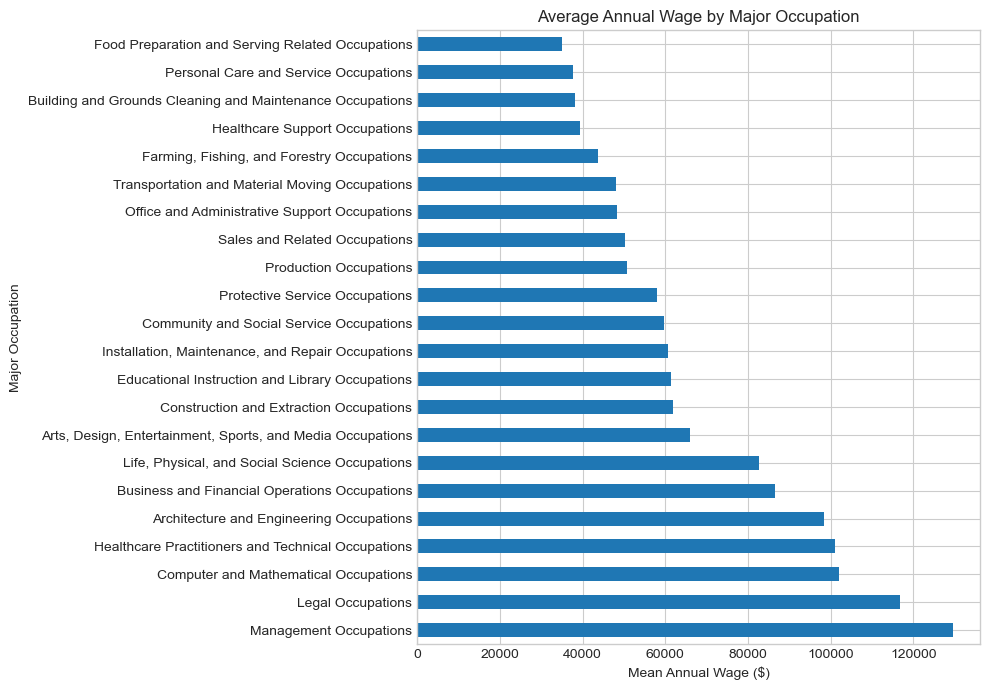

In [18]:
occupation_wage = (
    df.groupby('OCC_TITLE')['A_MEAN']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 7))
occupation_wage.plot(kind='barh')

plt.xlabel('Mean Annual Wage ($)')
plt.ylabel('Major Occupation')
plt.title('Average Annual Wage by Major Occupation')
plt.tight_layout()
plt.show()

### 3.2 Mean Annual Wage by Location

#### Plot the ten areas with highest mean wage estimates.

In [19]:
geographic_wages = (
    df
    .groupby('AREA_TITLE')
    .agg(
        mean_wage=('A_MEAN', 'mean'),
        median_wage=('A_MEAN', 'median')
    )
    .sort_values('mean_wage', ascending=False)
)

highest_wage_locations = geographic_wages.head(10).sort_values('mean_wage')
highest_wage_locations

,mean_wage,median_wage
AREA_TITLE,,
Oregon,"73,865.909","65,410.000"
Maryland,"75,294.091","65,100.000"
Connecticut,"76,945.000","67,375.000"
Colorado,"78,940.909","65,685.000"
New Jersey,"79,135.000","70,385.000"
Massachusetts,"82,620.909","69,230.000"
Washington,"82,903.182","73,155.000"
New York,"83,557.727","70,905.000"
California,"85,740.455","73,535.000"


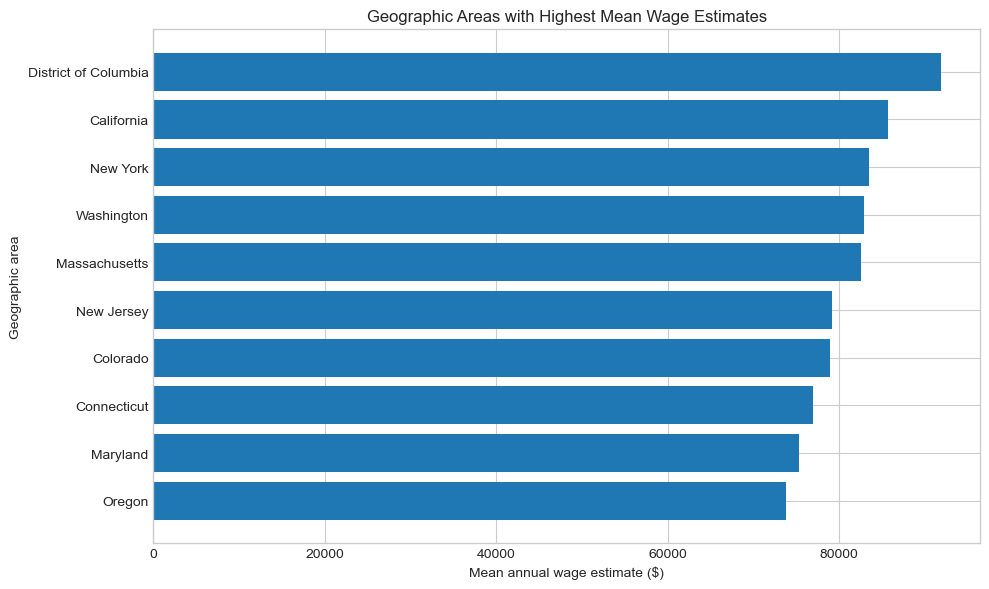

In [20]:
plt.figure(figsize=(10, 6))
plt.barh(highest_wage_locations.index, highest_wage_locations['mean_wage'])
plt.xlabel('Mean annual wage estimate ($)')
plt.ylabel('Geographic area')
plt.title('Geographic Areas with Highest Mean Wage Estimates')
plt.tight_layout()
plt.show()

#### Plot the ten areas with lowest mean wage estimates.

In [21]:
lowest_wage_locations = geographic_wages.tail(10).sort_values('mean_wage')

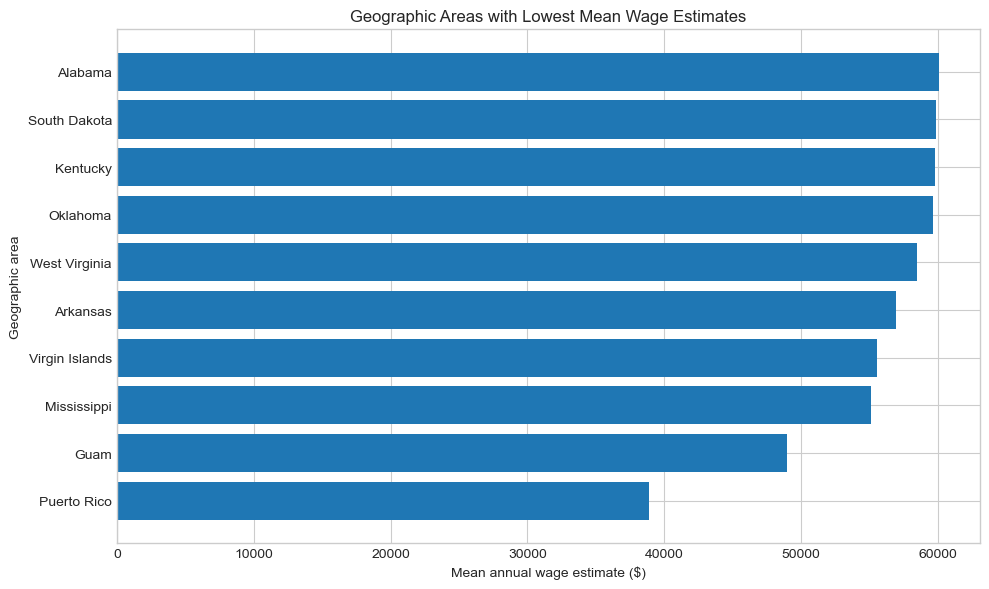

In [22]:
plt.figure(figsize=(10, 6))
plt.barh(lowest_wage_locations.index, lowest_wage_locations['mean_wage'])
plt.xlabel('Mean annual wage estimate ($)')
plt.ylabel('Geographic area')
plt.title('Geographic Areas with Lowest Mean Wage Estimates')
plt.tight_layout()
plt.show()

**Insight:** Average occupational wage estimates vary substantially across geographic areas. The geographic differences suggest that location provides meaningful additional information for wage benchmarking.

### 3.3 Mean Annual Wage by Employment Size

#### Distribution of Occupational Employment Estimates

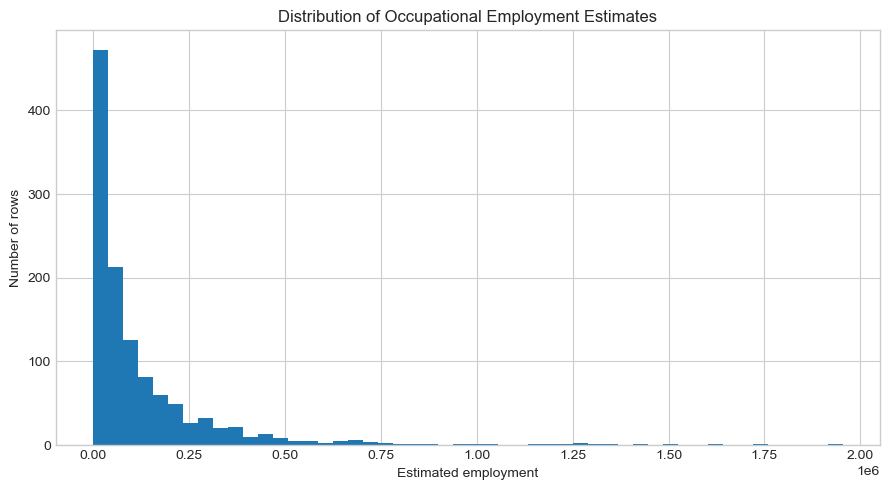

In [23]:
# Inspect the skew in employment 
plt.figure(figsize=(9, 5))
plt.hist(df['TOT_EMP'], bins=50)
plt.title('Distribution of Occupational Employment Estimates')
plt.xlabel('Estimated employment')
plt.ylabel('Number of rows')
plt.tight_layout()
plt.show()

Employment size is highly right-skewed, with a small number of observations representing much larger employment sizes. A log transformation is therefore applied to reduce the influence of extreme values and provide a more suitable scale for regression analysis.

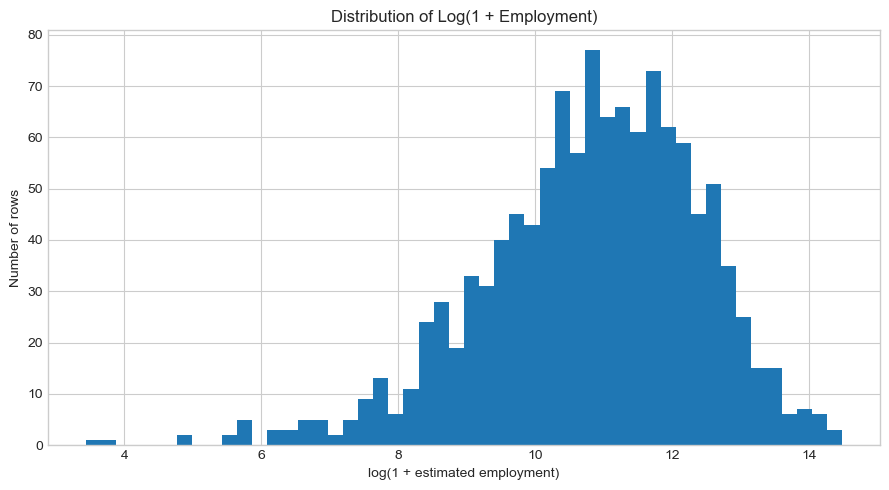

In [24]:
# log1p compresses large values and is defined when employment equals zero.
df['LOG_TOT_EMP'] = np.log1p(df['TOT_EMP'])
plt.figure(figsize=(9, 5))
plt.hist(df['LOG_TOT_EMP'], bins=50)
plt.title('Distribution of Log(1 + Employment)')
plt.xlabel('log(1 + estimated employment)')
plt.ylabel('Number of rows')
plt.tight_layout()
plt.show()

#### Relationship Between Employment Size and Mean Annual Wage

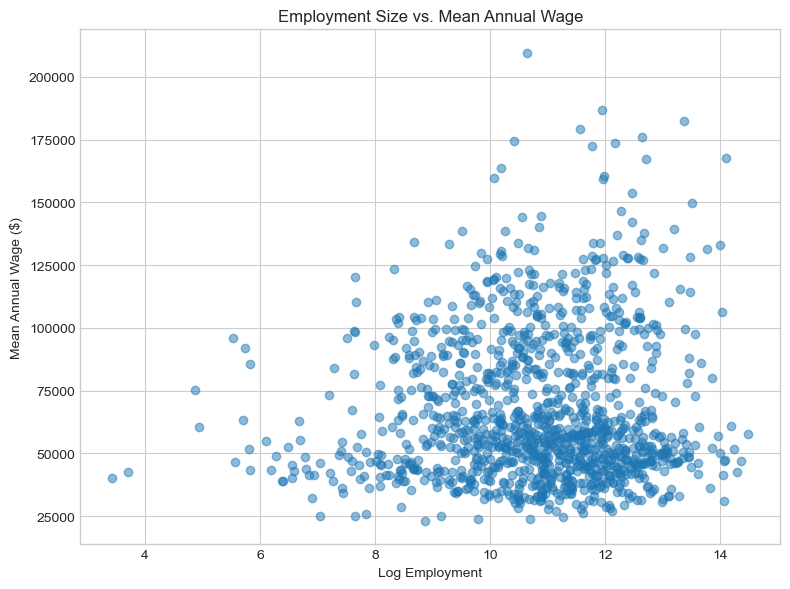

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df['LOG_TOT_EMP'],
    df['A_MEAN'],
    alpha=0.5
)

plt.xlabel('Log Employment')
plt.ylabel('Mean Annual Wage ($)')
plt.title('Employment Size vs. Mean Annual Wage')
plt.tight_layout()
plt.show()

In [26]:
employment_corr, employment_p = pearsonr(
    df['TOT_EMP'],
    df['A_MEAN']
)

log_employment_corr, log_employment_p = pearsonr(
    df['LOG_TOT_EMP'],
    df['A_MEAN']
)

print('Employment vs. Wage')
print('Pearson r:', employment_corr)
print('p-value:', employment_p)

print('\nLog Employment vs. Wage')
print('Pearson r:', log_employment_corr)
print('p-value:', log_employment_p)

Employment vs. Wage
Pearson r: 0.01495664326857414
p-value: 0.6068550942117857

Log Employment vs. Wage
Pearson r: 0.05181882593266798
p-value: 0.07444452089533107


#### Findings:

The sample shows a negligible positive linear correlation between employment size and annual wages (r = 0.015). However, this correlation is not statistically significant at the 5% level (p-value = 0.607), so there is insufficient evidence to conclude that a linear correlation exists in the population.

The log transformation slightly strengthens the relationship, but the sample correlation remains very weak (r = 0.052) and is not statistically significant (p-value = 0.074).

These results suggest that employment size has little standalone linear association with annual wages in this sample. Its incremental explanatory value is evaluated further using multiple linear regression, controlling for occupation and geography.


## 4. Standalone Explanatory Power of Individual Variables

* Evaluate the standalone relationship between each explanatory variable and mean annual wage
* Compare individual variables using R² and adjusted R²
* Identify which variable provides the strongest standalone explanatory power

In [27]:
occupation_model = smf.ols(
    'A_MEAN ~ C(OCC_TITLE)',
    data=df
).fit()

geography_model = smf.ols(
    'A_MEAN ~ C(AREA_TITLE)',
    data=df
).fit()

employment_model = smf.ols(
    'A_MEAN ~ LOG_TOT_EMP',
    data=df
).fit()

#A_MEAN: the target variable (annual wage).
#~: explained by.
#C(OCC_TITLE): treat occupation title as a categorical variable, not a continuous number.

In [28]:
#Which variable has the strongest standalone relationship with wage?
comparison = pd.DataFrame({
    'Factor': [
        'Major Occupation',
        'Geography',
        'Log Employment Size'
    ],
    'R_squared': [
        occupation_model.rsquared,
        geography_model.rsquared,
        employment_model.rsquared
    ],
    'Adjusted_R_squared': [
        occupation_model.rsquared_adj,
        geography_model.rsquared_adj,
        employment_model.rsquared_adj
    ]
}).sort_values('R_squared', ascending=False)

comparison

,Factor,R_squared,Adjusted_R_squared
0,Major Occupation,0.838,0.835
1,Geography,0.097,0.055
2,Log Employment Size,0.003,0.002


#### Findings:

- **Major Occupation:** Explains approximately **83.8%** of the variation in mean annual wages, making it the strongest standalone predictor among the three factors.
- **Geography:** Explains approximately **9.7%** of the variation, indicating that wage levels also differ meaningfully across geographic areas.
- **Log Employment:** Explains only approximately **0.3%** of the variation, suggesting that employment size has very limited standalone predictive power for mean annual wages.

**Conclusion:** Major occupation is the most informative factor for understanding wage differences when each variable is analyzed separately. Geography provides some explanatory value, while employment size alone explains very little. 

The standalone models establish which factor has the strongest individual relationship with wage. The next step is to determine whether geography and employment size add explanatory power after occupation is already accounted for.

## 5. Progressive Multiple Linear Regression

Progressive regression models are a series of regression models where you add predictors step by step to see how much each addition improves the model's ability to explain the outcome.

* Model 1: Major Occupation → R²
* Model 2: Major Occupation + Geography → Incremental R²
* Model 3: Major Occupation + Geography + Employment → Incremental R²
* Evaluate how much additional explanatory power each variable provides after accounting for variables already in the model

### 5.1 Comparing Model Fit and Incremental Explanatory Power

In [29]:
# Model 1: Major Occupation
model_1 = smf.ols(
    'A_MEAN ~ C(OCC_TITLE)',
    data=df
).fit()

# Model 2: Major Occupation + Geography
model_2 = smf.ols(
    'A_MEAN ~ C(OCC_TITLE) + C(AREA_TITLE)',
    data=df
).fit()

# Model 3: Major Occupation + Geography + Employment
model_3 = smf.ols(
    'A_MEAN ~ C(OCC_TITLE) + C(AREA_TITLE) + LOG_TOT_EMP',
    data=df
).fit()

In [30]:
model_comparison = pd.DataFrame({
    'Model': [
        'Major Occupation',
        'Major Occupation + Geography',
        'Major Occupation + Geography + Employment Size'
    ],
    'R_squared': [
        model_1.rsquared,
        model_2.rsquared,
        model_3.rsquared
    ],
    'Adjusted_R_squared': [
        model_1.rsquared_adj,
        model_2.rsquared_adj,
        model_3.rsquared_adj
    ],
    'AIC': [
        model_1.aic,
        model_2.aic,
        model_3.aic
    ]
})

model_comparison

,Model,R_squared,Adjusted_R_squared,AIC
0,Major Occupation,0.838,0.835,"25,651.039"
1,Major Occupation + Geography,0.932,0.927,"24,730.124"
2,Major Occupation + Geography + Employment Size,0.937,0.933,"24,634.733"


In [31]:
incremental_r2 = pd.DataFrame({
    'Added Variable': [
        'Major Occupation',
        'Geography',
        'Employment Size'
    ],
    'Incremental R²': [
        model_1.rsquared,
        model_2.rsquared - model_1.rsquared,
        model_3.rsquared - model_2.rsquared
    ]
})

display(incremental_r2)

,Added Variable,Incremental R²
0,Major Occupation,0.838
1,Geography,0.094
2,Employment Size,0.005


#### Multiple Linear Regression Findings

Major occupation is the strongest explanatory factor in the initial model, accounting for approximately 83.8% of observed wage variation. Adding geography increases R² by 9.4 percentage points, indicating that geographic differences provide substantial explanatory value beyond occupation. Adding employment size increases R² by a further 0.54 percentage points, suggesting very little additional explanatory power after accounting for occupation and geography.

However, AIC decreases from 25,651 in the occupation-only model to 24,634 in the full model. This indicates that both geography and employment size improve the balance between model fit and complexity among the models evaluated. Therefore, employment size is retained in the final model, although its incremental contribution to explanatory power is modest.

These results describe associations in the May 2024 occupational wage estimates and do not imply that geography or employment size causes wages to change.

### 5.2 Interpreting Regression Coefficients

In [32]:
coefficients = (
    model_3.params
    .to_frame('Coefficient')
)

coefficients.head(5)

,Coefficient
Intercept,"17,569.513"
"C(OCC_TITLE)[T.Arts, Design, Entertainment, Sports, and Media Occupations]","-30,260.520"
C(OCC_TITLE)[T.Building and Grounds Cleaning and Maintenance Occupations],"-64,872.643"
C(OCC_TITLE)[T.Business and Financial Operations Occupations],"-21,333.205"
C(OCC_TITLE)[T.Community and Social Service Occupations],"-38,858.106"


In [33]:
significance = pd.DataFrame({
    'Coefficient': model_3.params,
    'P-value': model_3.pvalues
})

significance = (
    significance[significance['P-value'] < 0.05]
    .sort_values('Coefficient', ascending=False)
)

# Top 10 significant geographic area coefficients
area_significance = significance[significance.index.str.contains('AREA_TITLE', regex=False)]
# regex=False tells Python to treat 'AREA_TITLE' as literal text, rather than interpreting it as a regular expression pattern.
display(area_significance.head(5))

# Top 10 significant occupation coefficients
occupation_significance = significance[significance.index.str.contains('OCC_TITLE', regex=False)]
display(occupation_significance.head(5))

employment_size_significance = significance[significance.index.str.contains('LOG_TOT_EMP', regex=False)]
display(employment_size_significance.head(5))

,Coefficient,P-value
C(AREA_TITLE)[T.District of Columbia],"40,202.966",0.000
C(AREA_TITLE)[T.Alaska],"26,777.233",0.000
C(AREA_TITLE)[T.Virgin Islands],"25,714.207",0.000
C(AREA_TITLE)[T.Rhode Island],"22,145.262",0.000
C(AREA_TITLE)[T.Delaware],"21,267.718",0.000


,Coefficient,P-value
C(OCC_TITLE)[T.Legal Occupations],"23,490.315",0.000
C(OCC_TITLE)[T.Management Occupations],"21,234.933",0.000
C(OCC_TITLE)[T.Healthcare Practitioners and Technical Occupations],"-6,751.921",0.000
"C(OCC_TITLE)[T.Life, Physical, and Social Science Occupations]","-12,118.461",0.000
C(OCC_TITLE)[T.Business and Financial Operations Occupations],"-21,333.205",0.000


,Coefficient,P-value
LOG_TOT_EMP,"7,086.030",0.000


In [34]:
#find references
print(model_3.model.data.design_info)

DesignInfo(['Intercept',
            'C(OCC_TITLE)[T.Arts, Design, Entertainment, Sports, and Media Occupations]',
            'C(OCC_TITLE)[T.Building and Grounds Cleaning and Maintenance Occupations]',
            'C(OCC_TITLE)[T.Business and Financial Operations Occupations]',
            'C(OCC_TITLE)[T.Community and Social Service Occupations]',
            'C(OCC_TITLE)[T.Computer and Mathematical Occupations]',
            'C(OCC_TITLE)[T.Construction and Extraction Occupations]',
            'C(OCC_TITLE)[T.Educational Instruction and Library Occupations]',
            'C(OCC_TITLE)[T.Farming, Fishing, and Forestry Occupations]',
            'C(OCC_TITLE)[T.Food Preparation and Serving Related Occupations]',
            'C(OCC_TITLE)[T.Healthcare Practitioners and Technical Occupations]',
            'C(OCC_TITLE)[T.Healthcare Support Occupations]',
            'C(OCC_TITLE)[T.Installation, Maintenance, and Repair Occupations]',
            'C(OCC_TITLE)[T.Legal Occupations]',


Reference categories: **Architecture and Engineering Occupations for occupation and Alabama for geographic area.** Regression coefficients represent estimated wage differences relative to these reference categories, holding the other variables constant.

#### Findings:

- **Occupational differences:** Legal Occupations have an estimated mean annual wage approximately $23,490 higher than Architecture and Engineering Occupations, controlling for geographic area and employment size (p < 0.001).

- **Geographic differences:** The District of Columbia has an estimated mean annual wage approximately $40,203 higher than Alabama, controlling for occupation and employment size (p < 0.001).

- **Employment size differences:** Holding occupation and geographic area constant, a one-unit increase in log employment size is associated with an estimated $7,086 increase in mean annual wages. This coefficient is statistically significant at the 5% significance level (p < 0.001), providing strong evidence of a positive association in the regression model. However, this association does not imply causation.

## 6. Predictive Modeling: Linear Regression, Decision Tree, and Random Forest

The previous analysis examined how major occupation, geographic area, and employment size are associated with differences in mean annual wages. The next step is to evaluate whether these variables can accurately predict wages for observations not used to train the model.

This section compares Linear Regression, Decision Tree Regression, and Random Forest Regression using the same training and test datasets. Model performance is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and test-set R².

The objective is to identify which model produces the most accurate wage predictions on unseen data, compared with a simple baseline model.

### 6.1 Train/Test Split and Feature Preprocessing

In [35]:
# Select the predictors and target variable.
features = [
    'OCC_TITLE',
    'AREA_TITLE',
    'LOG_TOT_EMP'
]

X = df[features]
y = df['A_MEAN']

# Split the data into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print('Training rows:', len(X_train))
print('Test rows:', len(X_test))

Training rows: 948
Test rows: 238


In [36]:
# Identify categorical and numerical predictors.
categorical_features = [
    'OCC_TITLE',
    'AREA_TITLE'
]

numerical_features = [
    'LOG_TOT_EMP'
]

# Encode categorical variables and keep the numerical variable unchanged.
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            'passthrough',
            numerical_features
        )
    ]
)

#handle_unknown='ignore' If a category appears in the test set but was not present in the training set, 
#the encoder can still transform the row instead of raising an error.

#'passthrough' tells scikit-learn not to transform those columns.

### 6.2 Baseline and Regression Models

In [37]:
baseline_model = DummyRegressor(strategy='mean')

# Model 1: Linear Regression.
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

# Model 2: Decision Tree Regression.
tree_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            DecisionTreeRegressor(
                random_state=42
            )
        )
    ]
)

# Model 3: Random Forest Regression.
forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# n_jobs=-1 can speed up model training by using multiple CPU cores. 
# It doesn't change the model's intended behavior or automatically improve prediction accuracy.

# n_estimators controls the number of trees in a Random Forest. It is a hyperparameter that can be tuned to balance predictive performance and computational cost.

# Train each model using only the training data.
models = {
    'Baseline': baseline_model,
    'Linear Regression': linear_model,
    'Decision Tree': tree_model,
    'Random Forest': forest_model
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'{name} trained.')

Baseline trained.
Linear Regression trained.
Decision Tree trained.
Random Forest trained.


### 6.3 Initial Model Comparison

In [44]:
# Generate predictions for every trained model.
predictions = {
    name: model.predict(X_test)
    for name, model in models.items()
}
#.items() gives you each key-value pair

results = []

for name, model_predictions in predictions.items():

    # Calculate the evaluation metrics.
    mae = mean_absolute_error(
        y_test,
        model_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            model_predictions
        )
    )

    r2 = r2_score(
        y_test,
        model_predictions
    )

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'Test R²': r2
    })

model_evaluation = (
    pd.DataFrame(results)
    .sort_values('MAE')
)

display(model_evaluation.round(3))

,Model,MAE,RMSE,Test R²
1,Linear Regression,"5,002.992","7,068.905",0.939
3,Random Forest,"5,657.658","8,287.973",0.916
2,Decision Tree,"6,985.798","10,385.454",0.868
0,Baseline,"22,885.965","28,627.400",-0.001


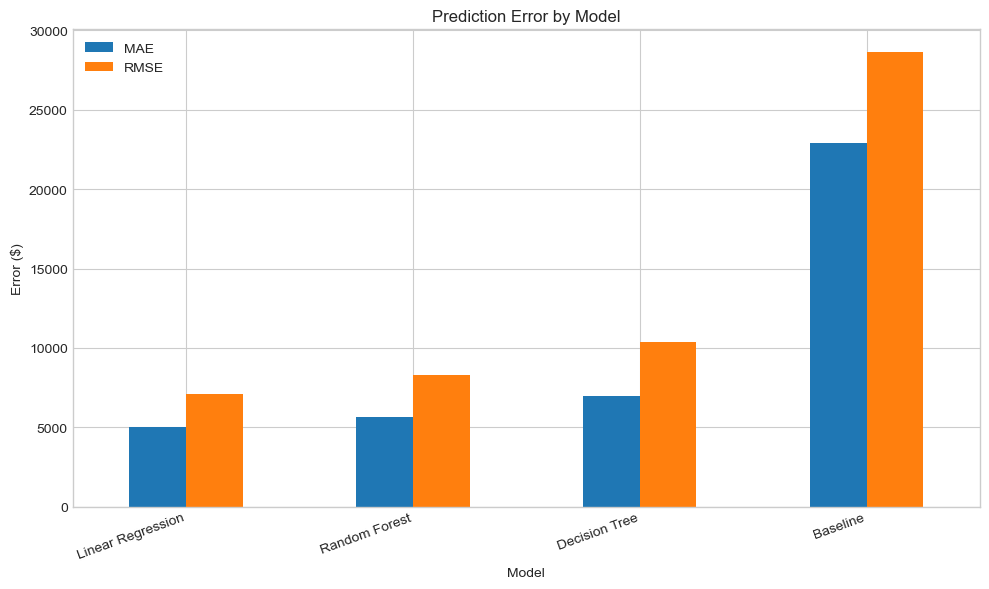

In [39]:
# Plot MAE and RMSE for each model.
model_evaluation.set_index('Model')[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Prediction Error by Model')
plt.xlabel('Model')
plt.ylabel('Error ($)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

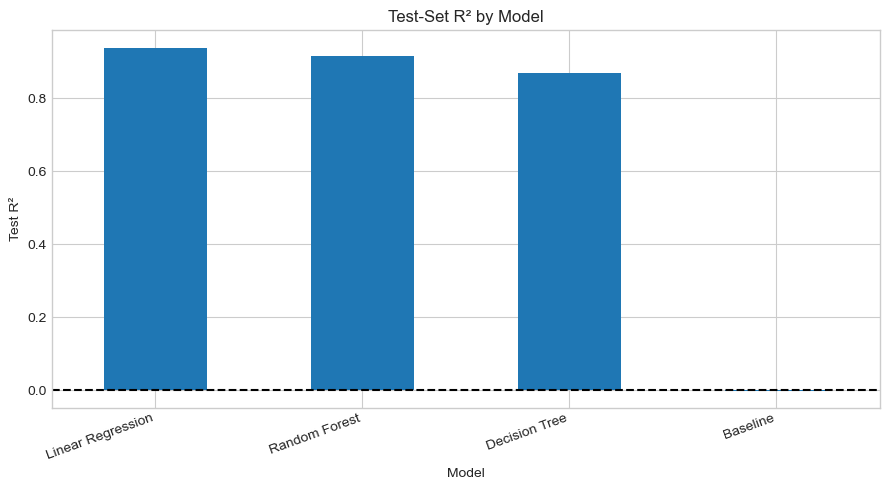

In [46]:
# Compare test-set R².
model_evaluation.set_index('Model')['Test R²'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.axhline(
    y=0,
    color='black',
    linestyle='--'
)

plt.title('Test-Set R² by Model')
plt.xlabel('Model')
plt.ylabel('Test R²')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 6.4 Hyperparameter Tuning

#### Decision Tree Regression: Hyperparameter Tuning

In [41]:
# Decision Tree: search for better model settings.
tree_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(random_state=42))
    ]
)

tree_parameters = {
    'model__max_depth': [None, 5, 10, 20],
    'model__min_samples_leaf': [1, 5, 10]
}

tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_parameters,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)

print('Best Decision Tree parameters:')
print(tree_search.best_params_)

print('Best cross-validation MAE:')
print(round(-tree_search.best_score_, 2))

Best Decision Tree parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1}
Best cross-validation MAE:
7813.4


#### Random Forest Regression: Hyperparameter Tuning

In [42]:
# Random Forest: search for better model settings.
forest_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

forest_parameters = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 5]
}

forest_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=forest_parameters,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print('Best Random Forest parameters:')
print(forest_search.best_params_)

print('Best cross-validation MAE:')
print(round(-forest_search.best_score_, 2))

Best Random Forest parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best cross-validation MAE:
6833.25


### 6.5 Final Model Evaluation and Comparison

In [43]:
# Use the best models selected by cross-validation.
tuned_models = {
    'Baseline': baseline_model,
    'Linear Regression': linear_model,
    'Tuned Decision Tree': tree_search.best_estimator_,
    'Tuned Random Forest': forest_search.best_estimator_
}

results = []

for name, model in tuned_models.items():

    # Generate predictions for the test set.
    test_predictions = model.predict(X_test)

    # Calculate evaluation metrics.
    mae = mean_absolute_error(y_test, test_predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    r2 = r2_score(y_test, test_predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'Test R²': r2
    })

# Compare models, ranked by test MAE.
tuned_model_evaluation = (
    pd.DataFrame(results)
    .sort_values('MAE')
    .reset_index(drop=True)
)

display(tuned_model_evaluation.round(3))

,Model,MAE,RMSE,Test R²
0,Linear Regression,"5,002.992","7,068.905",0.939
1,Tuned Random Forest,"5,657.658","8,287.973",0.916
2,Tuned Decision Tree,"6,985.798","10,385.454",0.868
3,Baseline,"22,885.965","28,627.400",-0.001


#### Findings:

Although hyperparameter tuning was performed using five-fold cross-validation, the best configurations for Decision Tree and Random Forest matched their initial settings. Consequently, tuning did not change their test-set performance. Linear Regression remained the best-performing model on the selected train/test split. Further validation using repeated splits or cross-validation can help assess the robustness of this ranking. Because the data represents aggregated May 2024 wage estimates, the model predicts wages across occupation-area observations rather than individual salaries or future wage trends.

## 7. Business Recommendations and Limitations

The Linear Regression model was selected because it achieved the lowest prediction error among the models evaluated, with a test-set MAE of `$5,003`, RMSE of `$7,069`, and R² of 0.939.

I recommend using the model as a preliminary wage-benchmarking tool to support labor-market comparisons and early-stage workforce budget planning. However, its predictions should not be treated as exact wage figures or used as the sole basis for individual compensation decisions.

The primary risk is that prediction errors may vary across occupations and geographic areas, potentially resulting in inaccurate wage comparisons or budget estimates. Before broader implementation, the business should review errors by occupation and location and compare the model's estimates against its actual use case. More granular salary data should be used when decisions require job-level precision.